#1. Set up

In [ ]:
! git clone https://github.com/gregdurrett/nyu-dsga1011-a2.git

Cloning into 'nyu-dsga1011-a2'...
remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (45/45), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 45 (delta 1), reused 45 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (45/45), 13.02 MiB | 20.83 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [ ]:
%cd /content/nyu-dsga1011-a2

/content/nyu-dsga1011-a2


In [ ]:
!pip install -q uv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 101.9 MB/s eta 0:00:00


In [ ]:
!uv run pytest

Using CPython 3.13.15 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Installed 63 packages in 611ms
============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: jaxtyping-0.3.2, json-report-1.5.0, metadata-3.1.1
collected 19 items                                                             

tests/test_data.py::test_get_batch FAILED
tests/test_model.py::test_linear FAILED
tests/test_model.py::test_embedding FAILED
tests/test_model.py::test_swiglu FAILED
tests/test_model.py::test_scaled_dot_product_attention FAILED
tests/test_model.py::test_4d_scaled_dot_product_attention FAILED
tests/test_model.py::test_multihead_self_attention FAILED
tests/test_model.py::test_multihead_self_attention_with_rope FAILED
tests/test_model.py::test_transformer_lm FAILED
tests/test_model.py::test_transformer_lm_truncated_input FAILED
t

In [ ]:
!uv run pytest -k test_linear

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: jaxtyping-0.3.2, json-report-1.5.0, metadata-3.1.1
collected 19 items / 18 deselected / 1 selected                                

tests/test_model.py::test_linear FAILED

=================================== FAILURES ===================================
_________________________________ test_linear __________________________________

numpy_snapshot = <tests.conftest.NumpySnapshot object at 0x7bc3943a46e0>
ts_state_dict = ({'layers.0.attn.k_proj.weight': tensor([[ 0.0890,  0.1049,  0.0980,  ...,  0.1314,  0.0594, -0.0206],
        [ 0.027...7,  ...,  0.0380, -0.0240,  0.1170]]), ...}, {'context_length': 16, 'd_ff': 128, 'd_model': 64, 'ffn_type': None, ...})
in_embeddings = tensor([[[-0.9414,  1.2632, -0.1838,  ..., -0.1941,  0.0048, -1.3165],
         [ 0.0204, -0.1652,  0.2109

#2. Build the Transformer

### 1. Linear Layer
: Transform input features using a weight matrix

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

Overwriting student/model.py


In [ ]:
%cd /content/nyu-dsga1011-a2
!uv run pytest tests/test_model.py::test_linear

/content/nyu-dsga1011-a2
============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: jaxtyping-0.3.2, json-report-1.5.0, metadata-3.1.1
collected 1 item                                                               

tests/test_model.py::test_linear PASSED

============================== 1 passed in 0.04s ===============================


###2. Embedding layer
: Look up a vector for each token ID
: R

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

Overwriting student/model.py


In [ ]:
%cd /content/nyu-dsga1011-a2
!uv run pytest tests/test_model.py::test_embedding

/content/nyu-dsga1011-a2
============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: jaxtyping-0.3.2, json-report-1.5.0, metadata-3.1.1
collected 1 item                                                               

tests/test_model.py::test_embedding PASSED

============================== 1 passed in 0.05s ===============================


### 3. RMSNorm
: Normalize activations

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):
    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    )
  def forward(self, x):
    in_dtype = x.type
    x = x.to(torch.float32)

    mean_square = (x * x).mean(dim=1, keepdim= True)
    rms = touch.sqrt(mean_square + self.eps)
    result = (x / rms) * self.weight

    return result.to(in_dtype)


Writing student/model.py


### 4. SwiGLU Feed-Forward Network
: Implement SiLU and the gated feed-forwared computation

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):

    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    ))
  def forward(self, x):
      in_dtype = x.dtype
      x = x.to(torch.float32)

      mean_square = (x * x).mean(dim=-1, keepdim=True)
      rms = torch.sqrt(mean_square + self.eps)
      result = (x / rms) * self.weight

      return result.to(in_dtype)
  def SiLU(x):
    return x * torch.sigmoid(x)

Overwriting student/model.py


###5. ROPE
: Add positional information by rotating query/key vectors

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):
    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    ))
  def forward(self, x):
      in_dtype = x.dtype
      x = x.to(torch.float32)

      mean_square = (x * x).mean(dim=-1, keepdim=True)
      rms = torch.sqrt(mean_square + self.eps)
      result = (x / rms) * self.weight

      return result.to(in_dtype)
  def SiLU(x):
    return x * torch.sigmoid(x)

Writing student/model.py


###6. Softmax
: Convert scores into probabilities ,with numerical stability

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):

    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    ))
  def forward(self, x):
      in_dtype = x.dtype
      x = x.to(torch.float32)

      mean_square = (x * x).mean(dim=-1, keepdim=True)
      rms = torch.sqrt(mean_square + self.eps)
      result = (x / rms) * self.weight

      return result.to(in_dtype)
  def SiLU(x):
    return x * torch.sigmoid(x)
  def softmax(x,dim):
    "Subtracting the largest score before exponentiating"
    max_values = x.max(dim=dim, keepdim=True).values
    shifted = x - max_values
    exp = torch.exp(shifted)
    return exp / exp.sum(dim=dim, keepdim=True)


Overwriting student/model.py


###7. Scaled Dot-Product Attention
: Implement attention with optional masking

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):

    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    ))
  def forward(self, x):
      in_dtype = x.dtype
      x = x.to(torch.float32)

      mean_square = (x * x).mean(dim=-1, keepdim=True)
      rms = torch.sqrt(mean_square + self.eps)
      result = (x / rms) * self.weight

      return result.to(in_dtype)


def silu(x):
    return x * torch.sigmoid(x)


def softmax(x, dim):

    max_values = x.max(dim=dim, keepdim=True).values
    shifted = x - max_values

    exp_values = torch.exp(shifted)
    return exp_values / exp_values.sum(dim=dim, keepdim=True)


def scaled_dot_product_attention(Q, K, V, mask=None):

    d_k = Q.shape[-1]

    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)


    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))


    attention_weights = softmax(scores, dim=-1)

    return attention_weights @ V



Writing student/model.py


### 8. Causual multi-head self atention
: Combine attention heads, prevent attention to future tokens and integrate RoPE

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):

    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    ))
  def forward(self, x):
      in_dtype = x.dtype
      x = x.to(torch.float32)

      mean_square = (x * x).mean(dim=-1, keepdim=True)
      rms = torch.sqrt(mean_square + self.eps)
      result = (x / rms) * self.weight

      return result.to(in_dtype)


def silu(x):
    return x * torch.sigmoid(x)


def softmax(x, dim):

    max_values = x.max(dim=dim, keepdim=True).values
    shifted = x - max_values

    exp_values = torch.exp(shifted)
    return exp_values / exp_values.sum(dim=dim, keepdim=True)


def scaled_dot_product_attention(Q, K, V, mask=None):

    d_k = Q.shape[-1]


    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)


    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))


    attention_weights = softmax(scores, dim=-1)

    return attention_weights @ V

class MultiHeadSelfAttention(nn.Module):
    def __init__(
        self, d_model, num_heads,
        max_seq_len=None, theta=None,
        device=None, dtype=None
    ):
        super().__init__()

        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads")

        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.q_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.k_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.v_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.output_proj = Linear(
            d_model, d_model, device=device, dtype=dtype
        )

        self.rope = None
        if theta is not None:
            if max_seq_len is None:
                raise ValueError("max_seq_len is required for RoPE")

            self.rope = RotaryPositionalEmbedding(
                theta=theta,
                d_k=self.d_k,
                max_seq_len=max_seq_len,
                device=device,
            )

    def forward(self, x, token_positions=None):
        seq_len = x.shape[-2]

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        head_shape = (*x.shape[:-1], self.num_heads, self.d_k)

        q = q.reshape(head_shape).transpose(-3, -2)
        k = k.reshape(head_shape).transpose(-3, -2)
        v = v.reshape(head_shape).transpose(-3, -2)

        if self.rope is not None:
            if token_positions is None:
                token_positions = torch.arange(
                    seq_len, device=x.device
                )

            positions = token_positions.unsqueeze(-2)
            q = self.rope(q, positions)
            k = self.rope(k, positions)

        indices = torch.arange(seq_len, device=x.device)
        causal_mask = indices[:, None] >= indices[None, :]

        attended = scaled_dot_product_attention(
            q, k, v, mask=causal_mask
        )

        merged = attended.transpose(-3, -2).reshape(x.shape)

        return self.output_proj(merged)

### 9. Transformer Block
: Combine normalization, attention, feed-forward layers, and residual connections.

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):
    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    ))
  def forward(self, x):
      in_dtype = x.dtype
      x = x.to(torch.float32)

      mean_square = (x * x).mean(dim=-1, keepdim=True)
      rms = torch.sqrt(mean_square + self.eps)
      result = (x / rms) * self.weight

      return result.to(in_dtype)


def silu(x):
    return x * torch.sigmoid(x)


def softmax(x, dim):
    max_values = x.max(dim=dim, keepdim=True).values
    shifted = x - max_values

    exp_values = torch.exp(shifted)
    return exp_values / exp_values.sum(dim=dim, keepdim=True)


def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]

    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))

    attention_weights = softmax(scores, dim=-1)

    return attention_weights @ V

class MultiHeadSelfAttention(nn.Module):
    def __init__(
        self, d_model, num_heads,
        max_seq_len=None, theta=None,
        device=None, dtype=None
    ):
        super().__init__()

        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads")

        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.q_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.k_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.v_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.output_proj = Linear(
            d_model, d_model, device=device, dtype=dtype
        )

        self.rope = None
        if theta is not None:
            if max_seq_len is None:
                raise ValueError("max_seq_len is required for RoPE")

            self.rope = RotaryPositionalEmbedding(
                theta=theta,
                d_k=self.d_k,
                max_seq_len=max_seq_len,
                device=device,
            )

    def forward(self, x, token_positions=None):
        seq_len = x.shape[-2]

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        head_shape = (*x.shape[:-1], self.num_heads, self.d_k)

        q = q.reshape(head_shape).transpose(-3, -2)
        k = k.reshape(head_shape).transpose(-3, -2)
        v = v.reshape(head_shape).transpose(-3, -2)

        if self.rope is not None:
            if token_positions is None:
                token_positions = torch.arange(
                    seq_len, device=x.device
                )

            positions = token_positions.unsqueeze(-2)
            q = self.rope(q, positions)
            k = self.rope(k, positions)

        indices = torch.arange(seq_len, device=x.device)
        causal_mask = indices[:, None] >= indices[None, :]

        attended = scaled_dot_product_attention(
            q, k, v, mask=causal_mask
        )

        merged = attended.transpose(-3, -2).reshape(x.shape)

        return self.output_proj(merged)

class TransformerBlock(nn.Module):
    def __init__(
        self, d_model, num_heads, d_ff,
        max_seq_len, theta,
        device=None, dtype=None
    ):
        super().__init__()

        self.ln1 = RMSNorm(d_model, device=device, dtype=dtype)

        self.attn = MultiHeadSelfAttention(
            d_model=d_model,
            num_heads=num_heads,
            max_seq_len=max_seq_len,
            theta=theta,
            device=device,
            dtype=dtype,
        )

        self.ln2 = RMSNorm(d_model, device=device, dtype=dtype)

        self.ffn = SwiGLU(
            d_model, d_ff, device=device, dtype=dtype
        )

    def forward(self, x, token_positions=None):
        x = x + self.attn(self.ln1(x), token_positions)
        x = x + self.ffn(self.ln2(x))
        return x

### 10. Full Transformer LM
: Combine embeddings, blocks, final normalizaion and output projection

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):
    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    ))
  def forward(self, x):
      in_dtype = x.dtype
      x = x.to(torch.float32)

      mean_square = (x * x).mean(dim=-1, keepdim=True)
      rms = torch.sqrt(mean_square + self.eps)
      result = (x / rms) * self.weight

      return result.to(in_dtype)


def silu(x):
    return x * torch.sigmoid(x)


def softmax(x, dim):
    max_values = x.max(dim=dim, keepdim=True).values
    shifted = x - max_values

    exp_values = torch.exp(shifted)
    return exp_values / exp_values.sum(dim=dim, keepdim=True)


def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]

    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))

    attention_weights = softmax(scores, dim=-1)

    return attention_weights @ V

class MultiHeadSelfAttention(nn.Module):
    def __init__(
        self, d_model, num_heads,
        max_seq_len=None, theta=None,
        device=None, dtype=None
    ):
        super().__init__()

        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads")

        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.q_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.k_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.v_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.output_proj = Linear(
            d_model, d_model, device=device, dtype=dtype
        )

        self.rope = None
        if theta is not None:
            if max_seq_len is None:
                raise ValueError("max_seq_len is required for RoPE")

            self.rope = RotaryPositionalEmbedding(
                theta=theta,
                d_k=self.d_k,
                max_seq_len=max_seq_len,
                device=device,
            )

    def forward(self, x, token_positions=None):
        seq_len = x.shape[-2]

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        head_shape = (*x.shape[:-1], self.num_heads, self.d_k)

        q = q.reshape(head_shape).transpose(-3, -2)
        k = k.reshape(head_shape).transpose(-3, -2)
        v = v.reshape(head_shape).transpose(-3, -2)

        if self.rope is not None:
            if token_positions is None:
                token_positions = torch.arange(
                    seq_len, device=x.device
                )

            positions = token_positions.unsqueeze(-2)
            q = self.rope(q, positions)
            k = self.rope(k, positions)

        indices = torch.arange(seq_len, device=x.device)
        causal_mask = indices[:, None] >= indices[None, :]

        attended = scaled_dot_product_attention(
            q, k, v, mask=causal_mask
        )

        merged = attended.transpose(-3, -2).reshape(x.shape)

        return self.output_proj(merged)

class TransformerBlock(nn.Module):
    def __init__(
        self, d_model, num_heads, d_ff,
        max_seq_len, theta,
        device=None, dtype=None
    ):
        super().__init__()

        self.ln1 = RMSNorm(d_model, device=device, dtype=dtype)

        self.attn = MultiHeadSelfAttention(
            d_model=d_model,
            num_heads=num_heads,
            max_seq_len=max_seq_len,
            theta=theta,
            device=device,
            dtype=dtype,
        )

        self.ln2 = RMSNorm(d_model, device=device, dtype=dtype)

        self.ffn = SwiGLU(
            d_model, d_ff, device=device, dtype=dtype
        )

    def forward(self, x, token_positions=None):
        x = x + self.attn(self.ln1(x), token_positions)
        x = x + self.ffn(self.ln2(x))
        return x

%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):
    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    ))
  def forward(self, x):
      in_dtype = x.dtype
      x = x.to(torch.float32)

      mean_square = (x * x).mean(dim=-1, keepdim=True)
      rms = torch.sqrt(mean_square + self.eps)
      result = (x / rms) * self.weight

      return result.to(in_dtype)


def silu(x):
    return x * torch.sigmoid(x)


def softmax(x, dim):
    max_values = x.max(dim=dim, keepdim=True).values
    shifted = x - max_values

    exp_values = torch.exp(shifted)
    return exp_values / exp_values.sum(dim=dim, keepdim=True)


def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]

    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))

    attention_weights = softmax(scores, dim=-1)

    return attention_weights @ V

class MultiHeadSelfAttention(nn.Module):
    def __init__(
        self, d_model, num_heads,
        max_seq_len=None, theta=None,
        device=None, dtype=None
    ):
        super().__init__()

        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads")

        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.q_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.k_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.v_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.output_proj = Linear(
            d_model, d_model, device=device, dtype=dtype
        )

        self.rope = None
        if theta is not None:
            if max_seq_len is None:
                raise ValueError("max_seq_len is required for RoPE")

            self.rope = RotaryPositionalEmbedding(
                theta=theta,
                d_k=self.d_k,
                max_seq_len=max_seq_len,
                device=device,
            )

    def forward(self, x, token_positions=None):
        seq_len = x.shape[-2]

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        head_shape = (*x.shape[:-1], self.num_heads, self.d_k)

        q = q.reshape(head_shape).transpose(-3, -2)
        k = k.reshape(head_shape).transpose(-3, -2)
        v = v.reshape(head_shape).transpose(-3, -2)

        if self.rope is not None:
            if token_positions is None:
                token_positions = torch.arange(
                    seq_len, device=x.device
                )

            positions = token_positions.unsqueeze(-2)
            q = self.rope(q, positions)
            k = self.rope(k, positions)

        indices = torch.arange(seq_len, device=x.device)
        causal_mask = indices[:, None] >= indices[None, :]

        attended = scaled_dot_product_attention(
            q, k, v, mask=causal_mask
        )

        merged = attended.transpose(-3, -2).reshape(x.shape)

        return self.output_proj(merged)

class TransformerBlock(nn.Module):
    def __init__(
        self, d_model, num_heads, d_ff,
        max_seq_len, theta,
        device=None, dtype=None
    ):
        super().__init__()

        self.ln1 = RMSNorm(d_model, device=device, dtype=dtype)

        self.attn = MultiHeadSelfAttention(
            d_model=d_model,
            num_heads=num_heads,
            max_seq_len=max_seq_len,
            theta=theta,
            device=device,
            dtype=dtype,
        )

        self.ln2 = RMSNorm(d_model, device=device, dtype=dtype)

        self.ffn = SwiGLU(
            d_model, d_ff, device=device, dtype=dtype
        )

    def forward(self, x, token_positions=None):
        x = x + self.attn(self.ln1(x), token_positions)
        x = x + self.ffn(self.ln2(x))
        return x

  class TransformerLM(nn.Module):
    def __init__(
        self, vocab_size, context_length, d_model,
        num_layers, num_heads, d_ff, rope_theta,
        device=None, dtype=None
    ):
        super().__init__()

        self.context_length = context_length

        self.token_embeddings = Embedding(
            vocab_size, d_model, device=device, dtype=dtype
        )

        self.layers = nn.ModuleList([
            TransformerBlock(
                d_model=d_model,
                num_heads=num_heads,
                d_ff=d_ff,
                max_seq_len=context_length,
                theta=rope_theta,
                device=device,
                dtype=dtype,
            )
            for _ in range(num_layers)
        ])

        self.ln_final = RMSNorm(
            d_model, device=device, dtype=dtype
        )

        self.lm_head = Linear(
            d_model, vocab_size, device=device, dtype=dtype
        )

    def forward(self, token_ids):
        if token_ids.shape[-1] > self.context_length:
            raise ValueError("Input exceeds the model's context length")

        x = self.token_embeddings(token_ids)

        for layer in self.layers:
            x = layer(x)

        x = self.ln_final(x)
        return self.lm_head(x)

Overwriting student/model.py


In [ ]:
!uv run pytest tests/test_model.py tests/test_nn_utils.py::test_softmax_matches_pytorch

## 3. Building Training Components

## 1. Cross-Entropy Loss
: Measure next-token prediction error

In [ ]:
%%writefile student/model.py
import torch
from torch import nn
import math

class Linear(nn.Module):
  def __init__(self, in_features, out_features, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(out_features, in_features, device = device, dtype = dtype)
    )
    std = math.sqrt(2.0 / (in_features + out_features))
    nn.init.trunc_normal_(
        self.weight,
        mean = 0.0,
        std = std,
        a = -3 * std,
        b = 3 * std
    )

  def forward(self, x):
    return x @ self.weight.t()

class Embedding(nn.Module):
  def __init__(self, num_embeddings, embedding_dim, device = None, dtype = None):
    super().__init__()

    self.weight = nn.Parameter(
        torch.empty(
            num_embeddings, embedding_dim,
            device = device, dtype = dtype)
    )

    nn.init.trunc_normal_(

        self.weight,
        mean = 0.0,
        std = 1.0,
        a = -3,
        b = 3
    )

  def forward(self, token_ids):
      return self.weight[token_ids]

class RMSNorm(nn.Module):
  def __init__(self, d_model, eps = 1e-5, device = None, dtype = None):
    super().__init__()
    self.eps = eps
    self.weight = nn.Parameter(
        torch.ones(d_model, device = device, dtype = dtype
    ))
  def forward(self, x):
      in_dtype = x.dtype
      x = x.to(torch.float32)

      mean_square = (x * x).mean(dim=-1, keepdim=True)
      rms = torch.sqrt(mean_square + self.eps)
      result = (x / rms) * self.weight

      return result.to(in_dtype)


def silu(x):
    return x * torch.sigmoid(x)


def softmax(x, dim):
    max_values = x.max(dim=dim, keepdim=True).values
    shifted = x - max_values

    exp_values = torch.exp(shifted)
    return exp_values / exp_values.sum(dim=dim, keepdim=True)


def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]

    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))

    attention_weights = softmax(scores, dim=-1)

    return attention_weights @ V

class RotaryPositionalEmbedding(nn.Module):
    def __init__(self, theta, d_k, max_seq_len, device=None):
        super().__init__()
        if d_k % 2 != 0:
            raise ValueError("d_k must be even for pairwise rotations")
        pair_indices = torch.arange(
            0, d_k, 2, device=device, dtype=torch.float32
        )
        inv_freq = theta ** (-pair_indices / d_k)
        positions = torch.arange(
            max_seq_len, device=device, dtype=torch.float32
        )
        angles = positions[:, None] * inv_freq[None, :]
        self.register_buffer("cos", torch.cos(angles), persistent=False)
        self.register_buffer("sin", torch.sin(angles), persistent=False)

    def forward(self, x, token_positions):
        cos = self.cos[token_positions]
        sin = self.sin[token_positions]
        even = x[..., 0::2]
        odd = x[..., 1::2]
        rotated_even = even * cos - odd * sin
        rotated_odd = even * sin + odd * cos
        return torch.stack(
            (rotated_even, rotated_odd), dim=-1
        ).flatten(-2).to(x.dtype)


class SwiGLU(nn.Module):
    def __init__(self, d_model, d_ff=None, device=None, dtype=None):
        super().__init__()
        if d_ff is None:
            d_ff = 64 * math.ceil((8 * d_model) / (3 * 64))
        self.w1 = Linear(d_model, d_ff, device=device, dtype=dtype)
        self.w2 = Linear(d_ff, d_model, device=device, dtype=dtype)
        self.w3 = Linear(d_model, d_ff, device=device, dtype=dtype)

    def forward(self, x):
        gate = silu(self.w1(x))
        values = self.w3(x)
        return self.w2(gate * values)


class MultiHeadSelfAttention(nn.Module):
    def __init__(
        self, d_model, num_heads,
        max_seq_len=None, theta=None,
        device=None, dtype=None
    ):
        super().__init__()

        if d_model % num_heads != 0:
            raise ValueError("d_model must be divisible by num_heads")

        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.q_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.k_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.v_proj = Linear(d_model, d_model, device=device, dtype=dtype)
        self.output_proj = Linear(
            d_model, d_model, device=device, dtype=dtype
        )

        self.rope = None
        if theta is not None:
            if max_seq_len is None:
                raise ValueError("max_seq_len is required for RoPE")

            self.rope = RotaryPositionalEmbedding(
                theta=theta,
                d_k=self.d_k,
                max_seq_len=max_seq_len,
                device=device,
            )

    def forward(self, x, token_positions=None):
        seq_len = x.shape[-2]

        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)

        head_shape = (*x.shape[:-1], self.num_heads, self.d_k)

        q = q.reshape(head_shape).transpose(-3, -2)
        k = k.reshape(head_shape).transpose(-3, -2)
        v = v.reshape(head_shape).transpose(-3, -2)

        if self.rope is not None:
            if token_positions is None:
                token_positions = torch.arange(
                    seq_len, device=x.device
                )

            positions = token_positions.unsqueeze(-2)
            q = self.rope(q, positions)
            k = self.rope(k, positions)

        indices = torch.arange(seq_len, device=x.device)
        causal_mask = indices[:, None] >= indices[None, :]

        attended = scaled_dot_product_attention(
            q, k, v, mask=causal_mask
        )

        merged = attended.transpose(-3, -2).reshape(x.shape)

        return self.output_proj(merged)

class TransformerBlock(nn.Module):
    def __init__(
        self, d_model, num_heads, d_ff,
        max_seq_len, theta,
        device=None, dtype=None
    ):
        super().__init__()

        self.ln1 = RMSNorm(d_model, device=device, dtype=dtype)

        self.attn = MultiHeadSelfAttention(
            d_model=d_model,
            num_heads=num_heads,
            max_seq_len=max_seq_len,
            theta=theta,
            device=device,
            dtype=dtype,
        )

        self.ln2 = RMSNorm(d_model, device=device, dtype=dtype)

        self.ffn = SwiGLU(
            d_model, d_ff, device=device, dtype=dtype
        )

    def forward(self, x, token_positions=None):
        x = x + self.attn(self.ln1(x), token_positions)
        x = x + self.ffn(self.ln2(x))
        return x

class TransformerLM(nn.Module):
    def __init__(
        self, vocab_size, context_length, d_model,
        num_layers, num_heads, d_ff, rope_theta,
        device=None, dtype=None
    ):
        super().__init__()

        self.context_length = context_length

        self.token_embeddings = Embedding(
            vocab_size, d_model, device=device, dtype=dtype
        )

        self.layers = nn.ModuleList([
            TransformerBlock(
                d_model=d_model,
                num_heads=num_heads,
                d_ff=d_ff,
                max_seq_len=context_length,
                theta=rope_theta,
                device=device,
                dtype=dtype,
            )
            for _ in range(num_layers)
        ])

        self.ln_final = RMSNorm(
            d_model, device=device, dtype=dtype
        )

        self.lm_head = Linear(
            d_model, vocab_size, device=device, dtype=dtype
        )

    def forward(self, token_ids):
        if token_ids.shape[-1] > self.context_length:
            raise ValueError("Input exceeds the model's context length")

        x = self.token_embeddings(token_ids)

        for layer in self.layers:
            x = layer(x)

        x = self.ln_final(x)
        return self.lm_head(x)

def cross_entropy(inputs, targets):
    shifted = inputs - inputs.max(dim=-1, keepdim=True).values
    log_sum_exp = torch.log(torch.exp(shifted).sum(dim=-1))
    target_logits = shifted.gather(
        dim=-1, index=targets.unsqueeze(-1)
    ).squeeze(-1)
    return (log_sum_exp - target_logits).mean()


Overwriting student/model.py


In [ ]:
!uv run pytest tests/test_nn_utils.py::test_cross_entropy

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: metadata-3.1.1, jaxtyping-0.3.2, json-report-1.5.0
collected 1 item                                                               

tests/test_nn_utils.py::test_cross_entropy PASSED

============================== 1 passed in 0.02s ===============================


### 2. Learning-rate experiment
: Run the provided SGD example for 10 iterations with learning rates 10,100,1000

In [ ]:
import math
import torch


class SGD(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3):
        if lr < 0:
            raise ValueError(f"Invalid learning rate: {lr}")
        super().__init__(params, {"lr": lr})

    def step(self, closure=None):
        loss = None if closure is None else closure()

        for group in self.param_groups:
            lr = group["lr"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                state = self.state[p]
                t = state.get("t", 0)

                grad = p.grad.data
                p.data -= lr / math.sqrt(t + 1) * grad

                state["t"] = t + 1

        return loss


In [ ]:
torch.manual_seed(0)
initial_weights = 5 * torch.randn(10, 10)

for lr in [1, 10, 100, 1000]:
    weights = torch.nn.Parameter(initial_weights.clone())
    opt = SGD([weights], lr=lr)

    print(f"\nLearning rate: {lr}")

    for t in range(10):
        opt.zero_grad()
        loss = (weights ** 2).mean()
        print(f"Step {t}: loss = {loss.item():.6g}")
        loss.backward()
        opt.step()


Learning rate: 1
Step 0: loss = 26.2714
Step 1: loss = 25.2311
Step 2: loss = 24.5225
Step 3: loss = 23.9594
Step 4: loss = 23.4826
Step 5: loss = 23.0644
Step 6: loss = 22.6893
Step 7: loss = 22.3476
Step 8: loss = 22.0327
Step 9: loss = 21.7399

Learning rate: 10
Step 0: loss = 26.2714
Step 1: loss = 16.8137
Step 2: loss = 12.3943
Step 3: loss = 9.69725
Step 4: loss = 7.85477
Step 5: loss = 6.51251
Step 6: loss = 5.49243
Step 7: loss = 4.69344
Step 8: loss = 4.05316
Step 9: loss = 3.53075

Learning rate: 100
Step 0: loss = 26.2714
Step 1: loss = 26.2714
Step 2: loss = 4.50746
Step 3: loss = 0.107874
Step 4: loss = 1.10268e-16
Step 5: loss = 1.229e-18
Step 6: loss = 4.13848e-20
Step 7: loss = 2.46532e-21
Step 8: loss = 2.11491e-22
Step 9: loss = 2.3499e-23

Learning rate: 1000
Step 0: loss = 26.2714
Step 1: loss = 9483.98
Step 2: loss = 1.63803e+06
Step 3: loss = 1.82214e+08
Step 4: loss = 1.47593e+10
Step 5: loss = 9.31481e+11
Step 6: loss = 4.78192e+13
Step 7: loss = 2.05739e+15
St

### 3. AdamW optimizer
: Implement parameter updates and optimizer state

In [ ]:
%%writefile student/optimizer.py
import math
import torch


class AdamW(torch.optim.Optimizer):
    def __init__(
        self,
        params,
        lr=1e-3,
        betas=(0.9, 0.999),
        eps=1e-8,
        weight_decay=0.01,
    ):
        if lr < 0:
            raise ValueError("Learning rate must be nonnegative")
        if eps < 0:
            raise ValueError("eps must be nonnegative")
        if weight_decay < 0:
            raise ValueError("Weight decay must be nonnegative")
        if not all(0 <= beta < 1 for beta in betas):
            raise ValueError("Each beta must be in [0, 1)")

        defaults = {
            "lr": lr,
            "betas": betas,
            "eps": eps,
            "weight_decay": weight_decay,
        }
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group["lr"]
            beta1, beta2 = group["betas"]
            eps = group["eps"]
            weight_decay = group["weight_decay"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                grad = p.grad
                state = self.state[p]

                if len(state) == 0:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)

                state["t"] += 1
                t = state["t"]
                m = state["m"]
                v = state["v"]

                m.mul_(beta1).add_(grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                adjusted_lr = (
                    lr * math.sqrt(1 - beta2 ** t)
                    / (1 - beta1 ** t)
                )

                p.addcdiv_(m, v.sqrt() + eps, value=-adjusted_lr)
                p.mul_(1 - lr * weight_decay)

        return loss

Writing student/optimizer.py


In [ ]:
!uv run pytest tests/test_optimizer.py::test_adamw

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: metadata-3.1.1, jaxtyping-0.3.2, json-report-1.5.0
collected 1 item                                                               

tests/test_optimizer.py::test_adamw PASSED

============================== 1 passed in 1.85s ===============================


### 4. Learning-rate schedule
: Implement warmup followed by cosine decay

In [ ]:
%%writefile student/optimizer.py
import math
import torch


class AdamW(torch.optim.Optimizer):
    def __init__(
        self,
        params,
        lr=1e-3,
        betas=(0.9, 0.999),
        eps=1e-8,
        weight_decay=0.01,
    ):
        if lr < 0:
            raise ValueError("Learning rate must be nonnegative")
        if eps < 0:
            raise ValueError("eps must be nonnegative")
        if weight_decay < 0:
            raise ValueError("Weight decay must be nonnegative")
        if not all(0 <= beta < 1 for beta in betas):
            raise ValueError("Each beta must be in [0, 1)")

        defaults = {
            "lr": lr,
            "betas": betas,
            "eps": eps,
            "weight_decay": weight_decay,
        }
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group["lr"]
            beta1, beta2 = group["betas"]
            eps = group["eps"]
            weight_decay = group["weight_decay"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                grad = p.grad
                state = self.state[p]

                if len(state) == 0:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)

                state["t"] += 1
                t = state["t"]
                m = state["m"]
                v = state["v"]

                m.mul_(beta1).add_(grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                adjusted_lr = (
                    lr * math.sqrt(1 - beta2 ** t)
                    / (1 - beta1 ** t)
                )

                p.addcdiv_(m, v.sqrt() + eps, value=-adjusted_lr)
                p.mul_(1 - lr * weight_decay)

        return loss

def get_lr_cosine_schedule(
    it,
    max_learning_rate,
    min_learning_rate,
    warmup_iters,
    cosine_cycle_iters,
):
    if it < warmup_iters:
        return (it / warmup_iters) * max_learning_rate

    if it <= cosine_cycle_iters:
        progress = (
            (it - warmup_iters)
            / (cosine_cycle_iters - warmup_iters)
        )

        return min_learning_rate + 0.5 * (
            1 + math.cos(math.pi * progress)
        ) * (max_learning_rate - min_learning_rate)

    return min_learning_rate

Overwriting student/optimizer.py


In [ ]:
!uv run pytest tests/test_optimizer.py::test_get_lr_cosine_schedule

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: metadata-3.1.1, jaxtyping-0.3.2, json-report-1.5.0
collected 1 item                                                               

tests/test_optimizer.py::test_get_lr_cosine_schedule PASSED

============================== 1 passed in 0.02s ===============================


### 5. Graident Clipping
: Limit the total gradient norm

In [ ]:
%%writefile student/optimizer.py
import math
import torch


class AdamW(torch.optim.Optimizer):
    def __init__(
        self,
        params,
        lr=1e-3,
        betas=(0.9, 0.999),
        eps=1e-8,
        weight_decay=0.01,
    ):
        if lr < 0:
            raise ValueError("Learning rate must be nonnegative")
        if eps < 0:
            raise ValueError("eps must be nonnegative")
        if weight_decay < 0:
            raise ValueError("Weight decay must be nonnegative")
        if not all(0 <= beta < 1 for beta in betas):
            raise ValueError("Each beta must be in [0, 1)")

        defaults = {
            "lr": lr,
            "betas": betas,
            "eps": eps,
            "weight_decay": weight_decay,
        }
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr = group["lr"]
            beta1, beta2 = group["betas"]
            eps = group["eps"]
            weight_decay = group["weight_decay"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                grad = p.grad
                state = self.state[p]

                if len(state) == 0:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)

                state["t"] += 1
                t = state["t"]
                m = state["m"]
                v = state["v"]

                m.mul_(beta1).add_(grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                adjusted_lr = (
                    lr * math.sqrt(1 - beta2 ** t)
                    / (1 - beta1 ** t)
                )

                p.addcdiv_(m, v.sqrt() + eps, value=-adjusted_lr)
                p.mul_(1 - lr * weight_decay)

        return loss

def get_lr_cosine_schedule(
    it,
    max_learning_rate,
    min_learning_rate,
    warmup_iters,
    cosine_cycle_iters,
):
    if it < warmup_iters:
        return (it / warmup_iters) * max_learning_rate

    if it <= cosine_cycle_iters:
        progress = (
            (it - warmup_iters)
            / (cosine_cycle_iters - warmup_iters)
        )

        return min_learning_rate + 0.5 * (
            1 + math.cos(math.pi * progress)
        ) * (max_learning_rate - min_learning_rate)

    return min_learning_rate

@torch.no_grad()
def gradient_clipping(parameters, max_l2_norm):
    grads = [
        p.grad for p in parameters
        if p.grad is not None
    ]

    if not grads:
        return

    total_squared_norm = sum(
        (grad ** 2).sum() for grad in grads
    )
    total_norm = torch.sqrt(total_squared_norm)

    if total_norm > max_l2_norm:
        scale = max_l2_norm / (total_norm + 1e-6)

        for grad in grads:
            grad.mul_(scale)

Overwriting student/optimizer.py


In [ ]:
!uv run pytest tests/test_nn_utils.py::test_gradient_clipping

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: metadata-3.1.1, jaxtyping-0.3.2, json-report-1.5.0
collected 1 item                                                               

tests/test_nn_utils.py::test_gradient_clipping PASSED

=============================== warnings summary ===============================
tests/adapters.py:352
  /content/nyu-dsga1011-a2/tests/adapters.py:352: SyntaxWarning: invalid escape sequence '\T'
    rope_theta (float): The RoPE $\Theta$ parameter.

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
========================= 1 passed, 1 warning in 0.05s =========================


# 3. Load Data and Train

Implement get_batch
: Sample input sequences and targets shifted by one token

In [ ]:
%%writefile student/data.py
import numpy as np
import torch


def get_batch(dataset, batch_size, context_length, device):
    num_starts = len(dataset) - context_length

    if num_starts <= 0:
        raise ValueError("Dataset must contain more tokens than context_length")

    starts = np.random.randint(0, num_starts, size=batch_size)

    inputs = np.stack([
        dataset[start : start + context_length]
        for start in starts
    ])

    targets = np.stack([
        dataset[start + 1 : start + context_length + 1]
        for start in starts
    ])

    x = torch.tensor(inputs, dtype=torch.long, device=device)
    y = torch.tensor(targets, dtype=torch.long, device=device)

    return x, y

Writing student/data.py


In [ ]:
!uv run pytest tests/test_data.py::test_get_batch

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: metadata-3.1.1, jaxtyping-0.3.2, json-report-1.5.0
collected 1 item                                                               

tests/test_data.py::test_get_batch PASSED

=============================== warnings summary ===============================
tests/adapters.py:352
  /content/nyu-dsga1011-a2/tests/adapters.py:352: SyntaxWarning: invalid escape sequence '\T'
    rope_theta (float): The RoPE $\Theta$ parameter.

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
========================= 1 passed, 1 warning in 0.72s =========================


In [ ]:
%cd /content/nyu-dsga1011-a2
!uv run pytest tests/

/content/nyu-dsga1011-a2
============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.1, pluggy-1.6.0
rootdir: /content/nyu-dsga1011-a2
configfile: pyproject.toml
plugins: metadata-3.1.1, jaxtyping-0.3.2, json-report-1.5.0
collected 19 items                                                             

tests/test_data.py::test_get_batch PASSED
tests/test_model.py::test_linear PASSED
tests/test_model.py::test_embedding PASSED
tests/test_model.py::test_swiglu PASSED
tests/test_model.py::test_scaled_dot_product_attention PASSED
tests/test_model.py::test_4d_scaled_dot_product_attention PASSED
tests/test_model.py::test_multihead_self_attention PASSED
tests/test_model.py::test_multihead_self_attention_with_rope PASSED
tests/test_model.py::test_transformer_lm PASSED
tests/test_model.py::test_transformer_lm_truncated_input PASSED
tests/test_model.py::test_transformer_block PASSED
tests/test_model.py::test_rmsnorm PASSED
tests/tes

Load the provided TinyStories data using load_memmap_dataset

In [ ]:
%%writefile student/train.py
import csv
from pathlib import Path

import numpy as np
import torch

from data_utils import load_memmap_dataset
from student.data import get_batch
from student.model import TransformerLM, cross_entropy
from student.optimizer import (
    AdamW,
    get_lr_cosine_schedule,
    gradient_clipping,
)


def main():
    torch.manual_seed(0)
    np.random.seed(0)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Training device:", device, flush=True)

    dataset = load_memmap_dataset(
        "data/tinystories_valid.bin",
        "data/tinystories_valid.meta",
    )

    config = {
        "vocab_size": 10000,
        "context_length": 64,
        "d_model": 128,
        "num_layers": 2,
        "num_heads": 4,
        "d_ff": 384,
        "rope_theta": 10000.0,
    }

    assert 0 <= dataset.min()
    assert dataset.max() < config["vocab_size"]

    model = TransformerLM(**config, device=device)
    model.train()

    optimizer = AdamW(
        model.parameters(),
        lr=1e-3,
        betas=(0.9, 0.95),
        eps=1e-8,
        weight_decay=0.01,
    )

    batch_size = 16
    num_steps = 500
    history = []

    for step in range(num_steps):
        lr = get_lr_cosine_schedule(
            it=step,
            max_learning_rate=1e-3,
            min_learning_rate=1e-4,
            warmup_iters=20,
            cosine_cycle_iters=num_steps - 1,
        )
        for group in optimizer.param_groups:
            group["lr"] = lr

        x, y = get_batch(
            dataset,
            batch_size,
            config["context_length"],
            device,
        )

        optimizer.zero_grad()
        logits = model(x)
        loss = cross_entropy(logits, y)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss at step {step}")

        loss.backward()
        gradient_clipping(model.parameters(), max_l2_norm=1.0)
        optimizer.step()

        loss_value = loss.item()
        history.append((step + 1, loss_value))

        if step == 0 or (step + 1) % 25 == 0:
            print(
                f"Batch {step + 1}/{num_steps} | "
                f"loss={loss_value:.4f} | lr={lr:.6f}",
                flush=True,
            )

    output_dir = Path("outputs")
    output_dir.mkdir(exist_ok=True)

    with (output_dir / "training_loss.csv").open("w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["batches_processed", "loss"])
        writer.writerows(history)

    torch.save(
        {"config": config, "model_state_dict": model.state_dict()},
        output_dir / "model.pt",
    )

    print("Saved loss history and trained model.", flush=True)


if __name__ == "__main__":
    main()

Writing student/train.py


In [ ]:
!uv run python -m student.train

Training device: cuda
Batch 1/500 | loss=9.2272 | lr=0.000000
Batch 25/500 | loss=7.5566 | lr=0.001000
Batch 50/500 | loss=5.7202 | lr=0.000992
Batch 75/500 | loss=5.7961 | lr=0.000972
Batch 100/500 | loss=5.1179 | lr=0.000941
Batch 125/500 | loss=4.5944 | lr=0.000899
Batch 150/500 | loss=4.7078 | lr=0.000848
Batch 175/500 | loss=4.3039 | lr=0.000789
Batch 200/500 | loss=4.5559 | lr=0.000724
Batch 225/500 | loss=4.2672 | lr=0.000654
Batch 250/500 | loss=4.3956 | lr=0.000581
Batch 275/500 | loss=4.2018 | lr=0.000507
Batch 300/500 | loss=3.8889 | lr=0.000435
Batch 325/500 | loss=4.1853 | lr=0.000365
Batch 350/500 | loss=3.8364 | lr=0.000301
Batch 375/500 | loss=3.9741 | lr=0.000243
Batch 400/500 | loss=3.9697 | lr=0.000193
Batch 425/500 | loss=3.9563 | lr=0.000153
Batch 450/500 | loss=3.9904 | lr=0.000124
Batch 475/500 | loss=3.6621 | lr=0.000106
Batch 500/500 | loss=3.7778 | lr=0.000100
Saved loss history and trained model.


Plot loss versus batches processed

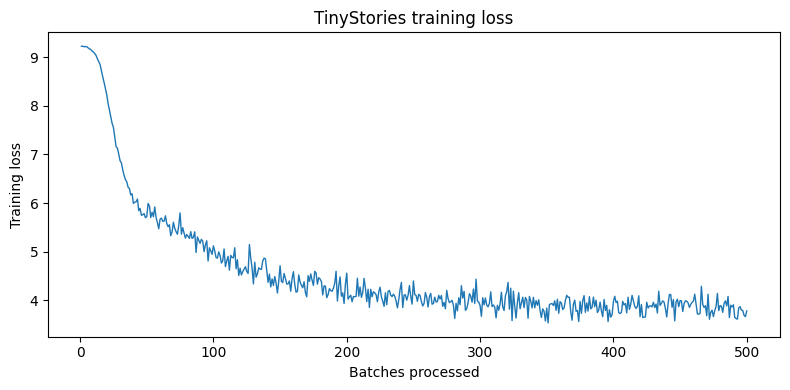

In [ ]:
import csv
import matplotlib.pyplot as plt

with open("outputs/training_loss.csv") as f:
    rows = list(csv.DictReader(f))

batches = [int(row["batches_processed"]) for row in rows]
losses = [float(row["loss"]) for row in rows]

plt.figure(figsize=(8, 4))
plt.plot(batches, losses, linewidth=1)
plt.xlabel("Batches processed")
plt.ylabel("Training loss")
plt.title("TinyStories training loss")
plt.tight_layout()
plt.savefig("outputs/training_loss.png", dpi=150)
plt.show()

# Generate Text


In [ ]:
%%writefile student/generate.py
import torch

from data_utils import load_memmap_dataset, load_vocab, decode
from student.model import TransformerLM, softmax


@torch.no_grad()
def generate(
    model,
    prompt_ids,
    max_new_tokens=100,
    temperature=1.0,
    top_p=0.9,
    eos_token_id=None,
):
    if temperature <= 0:
        raise ValueError("temperature must be positive")
    if not 0 < top_p <= 1:
        raise ValueError("top_p must be in (0, 1]")
    if max_new_tokens < 0:
        raise ValueError("max_new_tokens must be nonnegative")

    device = next(model.parameters()).device
    ids = torch.as_tensor(
        prompt_ids, dtype=torch.long, device=device
    )

    if ids.ndim != 1 or ids.numel() == 0:
        raise ValueError("Provide a nonempty, one-dimensional prompt")

    ids = ids.unsqueeze(0)
    was_training = model.training
    model.eval()

    try:
        for _ in range(max_new_tokens):
            context = ids[:, -model.context_length:]

            logits = model(context)[0, -1, :]
            probs = softmax(logits / temperature, dim=-1)

            if top_p < 1.0:
                sorted_probs, sorted_ids = torch.sort(
                    probs, descending=True
                )
                cumulative = torch.cumsum(sorted_probs, dim=-1)

                remove = cumulative > top_p
                remove[1:] = remove[:-1].clone()
                remove[0] = False

                filtered = sorted_probs.masked_fill(remove, 0.0)
                filtered = filtered / filtered.sum()

                sampled_index = torch.multinomial(filtered, 1)
                next_token = sorted_ids[sampled_index]
            else:
                next_token = torch.multinomial(probs, 1)

            ids = torch.cat([ids, next_token.reshape(1, 1)], dim=1)

            if (
                eos_token_id is not None
                and next_token.item() == eos_token_id
            ):
                break
    finally:
        model.train(was_training)

    return ids[0].tolist()


def main():
    torch.manual_seed(0)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    checkpoint = torch.load(
        "outputs/model.pt",
        map_location="cpu",
        weights_only=True,
    )

    model = TransformerLM(**checkpoint["config"])
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)

    vocab, _ = load_vocab("data/tinystories_vocab_merges.pt")

    eos_token_id = next(
        (token_id for token_id, value in vocab.items()
         if value == b"<|endoftext|>"),
        None,
    )
    if eos_token_id is None:
        raise ValueError("Could not find the end-of-text token")

    dataset = load_memmap_dataset(
        "data/tinystories_valid.bin",
        "data/tinystories_valid.meta",
    )

    prompt_ids = dataset[:12].tolist()

    output_ids = generate(
        model,
        prompt_ids,
        max_new_tokens=100,
        temperature=0.8,
        top_p=0.9,
        eos_token_id=eos_token_id,
    )

    print("PROMPT:")
    print(decode(prompt_ids, vocab))

    print("\nGENERATED CONTINUATION:")
    print(decode(output_ids[len(prompt_ids):], vocab))


if __name__ == "__main__":
    main()

Writing student/generate.py


In [ ]:
!uv run python -m student.generate

PROMPT:
u don't have to be scared of the loud dog,

GENERATED CONTINUATION:
 "I am a big dog. So, let's, they had to show her friends and their mom had to help, and the noise. The moral of the park, and Sam! The big bird tried to his favorite toy things.
Tom was a long time, and Lily went to his friend. She felt sad. They had a big smile and the bench, the cat.
Tim was a small dog. He said, "I love you, it is sorry." The dog wanted


The generated continuation contains recognizable story vocabulary and dialogue, but it frequently changes subjects and produces incomplete or ungrammatical phrases. The model has learned some local language patterns but does not yet maintain a coherent narrative.